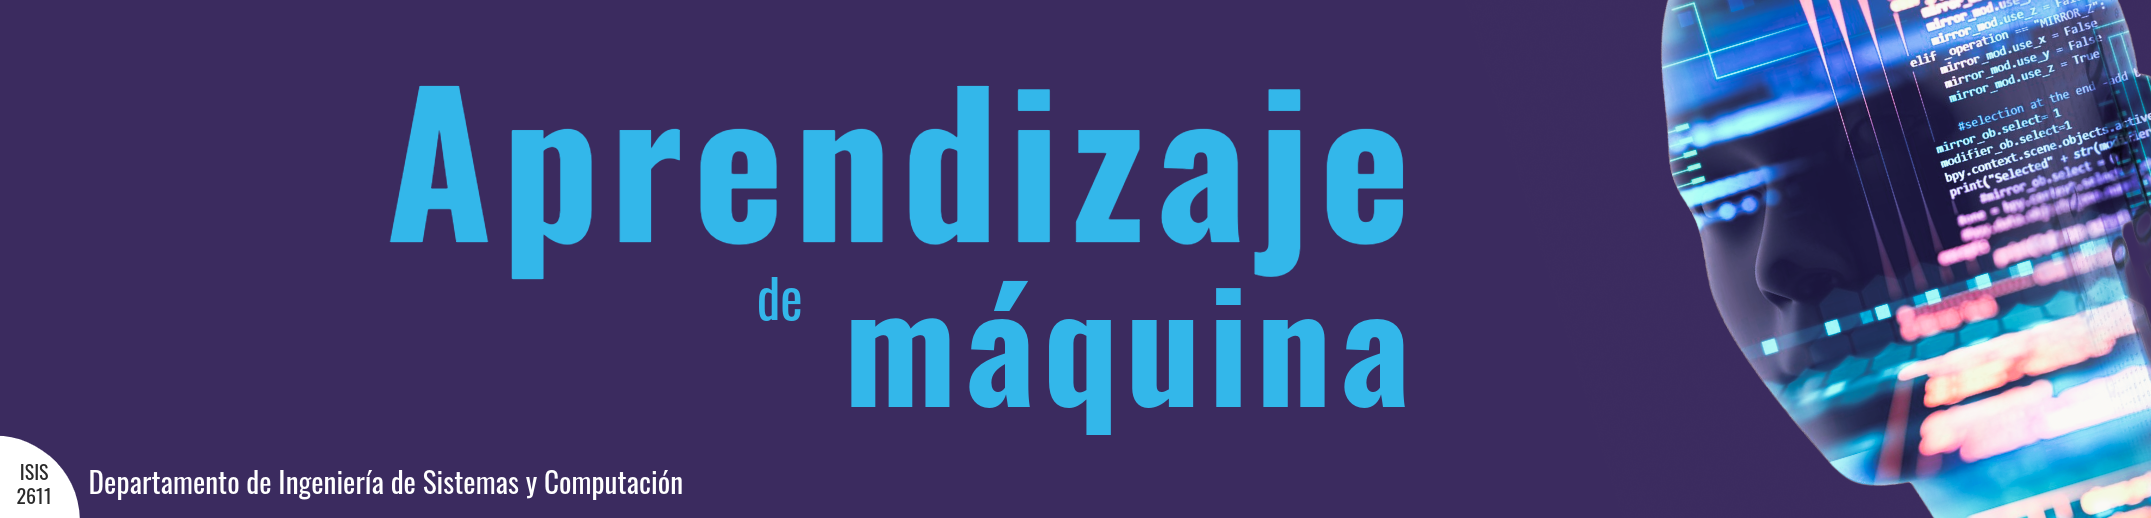

<div align="center">
  <h2>Perceptrón Multicapa (MLP) con TensorFlow y Keras</h2>
</div>

## Contexto y Objetivos
En esta práctica vamos a construir y analizar un clasificador de dígitos con una red neuronal tipo MLP. La idea no es solo ejecutar el modelo, sino entender por qué funciona, cómo se entrena y qué decisiones de diseño ayudan a que generalice mejor.

Trabajaremos con MNIST, un conjunto de imágenes de 28x28 en escala de grises, y compararemos dos versiones del modelo: una línea base sencilla y una versión mejorada con regularización y callbacks.

### Objetivos de Aprendizaje:
1. Comprender los fundamentos del Deep Learning y el aprendizaje de representación.
2. Entender la arquitectura y matemática del Perceptrón Multicapa (MLP).
3. Dominar el uso de funciones de activación, funciones de costo y optimizadores.
4. Implementar redes neuronales con TensorFlow/Keras.
5. Ajustar hiperparámetros sistemáticamente (capas, neuronas, *learning rate*, *batch size*).
6. Prevenir el *overfitting* mediante regularización y *Callbacks* (EarlyStopping, ModelCheckpoint).

---
## Guía de Configuración: Aceleración por Hardware

Para entrenar modelos de Deep Learning de manera eficiente, es fundamental aprovechar la aceleración por hardware (**GPU** o **TPU**). En Google Colab, puedes activar esto de la siguiente manera:

1. Dirígete al menú superior y selecciona **Entorno de ejecución** (Runtime).
2. Haz clic en **Cambiar tipo de entorno de ejecución** (Change runtime type).
3. En el desplegable de **Acelerador de hardware**, selecciona **T4 GPU** (recomendado para MLPs y CNNs estándar).
4. Haz clic en **Guardar**.

> **Nota:** La GPU (Graphics Processing Unit) está diseñada para el procesamiento en paralelo masivo, lo cual acelera drásticamente las multiplicaciones de matrices y el cálculo de gradientes en TensorFlow.

### Verificación del Entorno
Ejecuta la siguiente celda para confirmar que TensorFlow tiene acceso a la GPU:

In [1]:
import tensorflow as tf

# Verificar si hay GPUs disponibles
device_name = tf.test.gpu_device_name()

if device_name != '/device:GPU:0':
    print('GPU no encontrada. El entrenamiento será más lento (CPU mode).')
else:
    print(f'GPU encontrada en: {device_name}')

# Información detallada del hardware
!nvidia-smi -L

GPU no encontrada. El entrenamiento será más lento (CPU mode).


"nvidia-smi" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.


In [2]:
# Importación de librerías necesarias
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
from sklearn.metrics import confusion_matrix, classification_report

# Configuración de estilo para visualizaciones
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("notebook")

# Semilla de reproducibilidad, para que los resultados no cambien entre ejecuciones
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Verificar versión de TensorFlow
print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.21.0


# 2. Fundamentos Teóricos

Antes de programar el modelo, repasamos los conceptos mínimos que conectan la teoría con lo que veremos en el código.

## 2.1 ¿Qué es el Deep Learning?
Deep Learning es una rama de Machine Learning que usa redes neuronales con varias capas para aprender representaciones cada vez más útiles de los datos. En lugar de diseñar manualmente cada característica, el modelo aprende transformaciones intermedias durante el entrenamiento.

En visión por computador esto es especialmente útil: una red puede pasar de patrones simples (bordes o trazos) a estructuras más complejas que permiten distinguir clases, en este caso los dígitos del 0 al 9.




## 2.2 Redes Neuronales Artificiales (ANN) y el Perceptrón
Inspiradas en el cerebro biológico, las ANN están compuestas por nodos (neuronas). La unidad fundamental es el perceptrón, cuya matemática básica se define como una suma ponderada de las entradas, más un sesgo (*bias*), que luego pasa por una función de activación no lineal:

$$y = \sigma\left(\sum_{i=1}^{n} w_i x_i + b\right) = \sigma(W^T X + b)$$

Donde $W$ son los pesos, $X$ son las entradas, $b$ es el sesgo y $\sigma$ es la función de activación.



## 2.3 Perceptrón Multicapa (MLP)
Un MLP es una red neuronal prealimentada (*feedforward*) conformada por al menos tres capas de nodos:
1. **Capa de entrada (Input layer):** Recibe los datos crudos.
2. **Capas ocultas (Hidden layers):** Capas intermedias que procesan características complejas.
3. **Capa de salida (Output layer):** Emite la predicción final.
En un MLP estándar, las capas están **completamente conectadas**, lo que significa que cada neurona de una capa se conecta con todas las neuronas de la capa siguiente.

#### ¿Por qué la profundidad importa?
El Teorema de Aproximación Universal establece que una sola capa oculta con una cantidad suficiente de neuronas puede aproximar cualquier función continua. Sin embargo, en la práctica, preferimos redes profundas (varias capas) en lugar de redes anchas (una sola capa gigante).

**Justificación:**
1. **Jerarquía de características:** Las primeras capas aprenden rasgos simples (bordes, líneas), mientras que las capas profundas combinan esos rasgos para reconocer formas complejas (círculos, el dígito "8").
2. **Eficiencia de parámetros:** Una red profunda suele requerir exponencialmente menos neuronas que una red ancha para lograr el mismo nivel de complejidad, lo que optimiza el costo computacional.



## 2.4 Funciones de Activación
Sin funciones de activación, un MLP sería matemáticamente equivalente a un modelo de regresión lineal simple, sin importar cuántas capas tenga. La no-linealidad es crucial.
* **Sigmoid:** $\sigma(x) = \frac{1}{1+e^{-x}}$. Mapea valores entre 0 y 1. Sufre del problema de desvanecimiento del gradiente (*vanishing gradient*).
* **Tanh:** $\tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}$. Mapea valores entre -1 y 1.
* **ReLU (Rectified Linear Unit):** $\max(0, x)$. Es la más usada en capas ocultas. Eficiente computacionalmente.
* **Softmax:** Usada en la capa de salida para clasificación multiclase. Convierte los *logits* en probabilidades que suman 1: $$P(y=j|z) = \frac{e^{z_j}}{\sum_{k=1}^{K} e^{z_k}}$$
#### Recomendaciones Técnicas:
* **ReLU vs Sigmoid:** En redes profundas, la **Sigmoid** tiende a "saturar" (su derivada es casi cero para valores muy altos o bajos), lo que causa el problema de **Desvanecimiento del Gradiente** (*Vanishing Gradient*), deteniendo el aprendizaje. La **ReLU** soluciona esto al mantener un gradiente constante de 1 para todos los valores positivos.
* **Cuándo usar Softmax:** Solo debe usarse en la capa de salida para problemas donde las clases sean mutuamente excluyentes. Si una imagen pudiera contener varios números a la vez, usaríamos **Sigmoid** en la salida con una pérdida de tipo binario por neurona.


## 2.5 Funciones de Costo (Loss Functions)
Miden qué tan lejos está la predicción de la red del valor real.
* **MSE:** Para regresión. $MSE = \frac{1}{n} \sum_{i=1}^{n} (Y_i - \hat{Y}_i)^2$
* **Categorical Crossentropy:** Para clasificación multiclase (One-Hot). $L = -\sum_{i=1}^{C} y_i \log(\hat{y}_i)$
* **Sparse Categorical Crossentropy:** Igual a la anterior, pero optimizada computacionalmente cuando las etiquetas (labels) son enteros (0, 1, 2...).



## 2.6 Backpropagation y Optimización
El entrenamiento de la red se realiza mediante **Backpropagation** (propagación hacia atrás), que utiliza la **regla de la cadena** de cálculo diferencial para calcular el gradiente de la función de pérdida con respecto a cada peso de la red. Luego, un algoritmo de optimización (como Descenso de Gradiente) actualiza los pesos: $$W_{nuevo} = W_{viejo} - \eta \nabla L(W)$$
Donde $\eta$ es la tasa de aprendizaje (*learning rate*). Los optimizadores modernos como **Adam** o **RMSprop** ajustan dinámicamente este *learning rate* para cada parámetro basándose en momentos pasados, acelerando la convergencia.

## 2.7 Intuición de la Regularización
Existen técnicas como **Dropout** y **L2**, cuyo objetivo es reducir la **Varianza** (el error por sensibilidad al ruido del entrenamiento) a costa de un ligero aumento en el **Sesgo** (*Bias*).

1. **Dropout como Ensamble:** Al apagar neuronas aleatoriamente, el Dropout obliga a la red a no confiar en una sola "neurona experta". Matemáticamente, esto equivale a promediar las predicciones de miles de arquitecturas diferentes, lo que robustece el modelo final.
2. **Batch Normalization (BN):** BN soluciona el **Internal Covariate Shift**. Al normalizar las activaciones de cada capa para que tengan media 0 y varianza 1, permitimos el uso de *learning rates* más altos y reducimos la dependencia de una inicialización de pesos perfecta.

# 3. Carga y Exploración del Dataset MNIST

In [3]:
# MNIST contiene imágenes de 28x28 píxeles de dígitos escritos a mano (0-9)

(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras.datasets.mnist.load_data()

print(f"Shape of X_train_raw: {X_train_raw.shape}")
print(f"Shape of y_train_raw: {y_train_raw.shape}")
print(f"Shape of X_test_raw: {X_test_raw.shape}")

       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   32768/11490434 ━━━━━━━━━━━━━━━━━━━━ 18s 2us/step

   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 26s 2us/step

   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 25s 2us/step

  163840/11490434 ━━━━━━━━━━━━━━━━━━━━ 16s 1us/step

...

 9691136/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

10510336/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

11198464/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Shape of X_train_raw: (60000, 28, 28)
Shape of y_train_raw: (60000,)
Shape of X_test_raw: (10000, 28, 28)


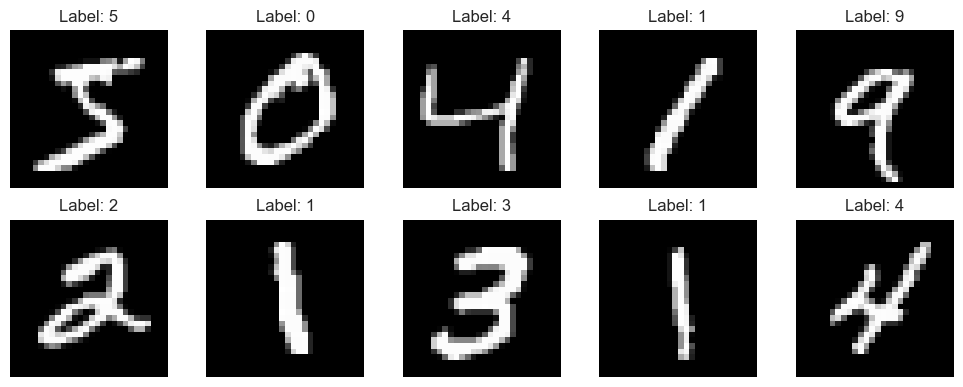

In [4]:
# Visualización de ejemplos del dataset
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
axes = axes.ravel()

for i in range(10):
    axes[i].imshow(X_train_raw[i], cmap='gray')
    axes[i].set_title(f"Label: {y_train_raw[i]}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [5]:
# Normalización de imágenes (0-255 -> 0-1)
# Esto estabiliza el entrenamiento y acelera la convergencia de la red
X_train = X_train_raw.astype('float32') / 255.0
X_test = X_test_raw.astype('float32') / 255.0

# Para un MLP clásico (Dense layers), necesitamos "aplanar" (flatten) las imágenes
# Pasamos de matrices 2D (28x28) a vectores 1D (784)
# Keras nos permite hacer esto directamente en la arquitectura con layers.Flatten(),
# pero mantendremos y_train y y_test intactos (Sparse Categorical Crossentropy)
y_train = y_train_raw
y_test = y_test_raw

# 4. Construcción del Primer MLP (Baseline)

Iniciaremos con una arquitectura sencilla para establecer un punto de referencia (*baseline*).
* **Entrada:** Capa `Flatten` para convertir 28x28 a 784.
* **Capa Oculta:** 1 capa con 128 neuronas y activación `ReLU`.
* **Salida:** 10 neuronas (una por clase) con activación `Softmax`.

## 4.1 Arquitectura Simple

In [6]:
def build_baseline_model():
    model = keras.Sequential([
        layers.Flatten(input_shape=(28, 28)),          # Capa de entrada
        layers.Dense(128, activation='relu'),          # Capa oculta
        layers.Dense(10, activation='softmax')         # Capa de salida multiclase
    ])

    # Compilación del modelo
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

baseline_model = build_baseline_model()
baseline_model.summary() # Visualización de la Arquitectura

C:\Users\opanadero\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 4.2 Entrenamiento

In [7]:

batch_size = 128
epochs = 15

# Usamos validation_split=0.2 para apartar el 20% de los datos para validación
history_baseline = baseline_model.fit(
    X_train, y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2,
    verbose=1
)

Epoch 1/15


  1/375 ━━━━━━━━━━━━━━━━━━━━ 8:47 1s/step - accuracy: 0.1172 - loss: 2.4526

 13/375 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4868 - loss: 1.8472 

 28/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6484 - loss: 1.3901

 43/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7129 - loss: 1.1322

...

345/375 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9979 - loss: 0.0146

353/375 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9979 - loss: 0.0145

361/375 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9979 - loss: 0.0145

374/375 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9980 - loss: 0.0145

375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9980 - loss: 0.0144 - val_accuracy: 0.9737 - val_loss: 0.0973


## 4.3 Evaluación Visual

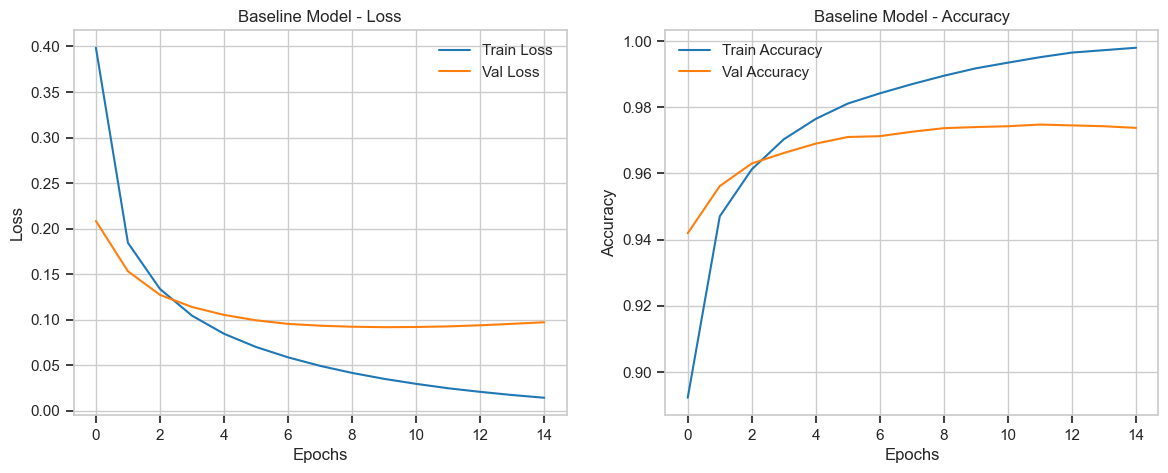

Test Accuracy: 0.9772


In [8]:

def plot_history(history, title="Model Performance"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Loss plot
    ax1.plot(history.history['loss'], label='Train Loss')
    ax1.plot(history.history['val_loss'], label='Val Loss')
    ax1.set_title(f'{title} - Loss')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()

    # Accuracy plot
    ax2.plot(history.history['accuracy'], label='Train Accuracy')
    ax2.plot(history.history['val_accuracy'], label='Val Accuracy')
    ax2.set_title(f'{title} - Accuracy')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy')
    ax2.legend()

    plt.show()

plot_history(history_baseline, "Baseline Model")

# Evaluación en el set de prueba
test_loss, test_acc = baseline_model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")

# 5. Experimentación con Hiperparámetros, Regularización y Callbacks

Entrenar redes profundas puede llevar a sobreajuste (*overfitting*). Implementaremos:
1.  **Dropout:** Apaga neuronas aleatoriamente durante el entrenamiento (probabilidad $p$) para evitar codependencias complejas.
2.  **EarlyStopping:** Detiene el entrenamiento si el modelo deja de mejorar en los datos de validación después de $N$ épocas (*patience*).
3.  **ModelCheckpoint:** Guarda los pesos del modelo de la mejor época.
4.  **ReduceLROnPlateau:** Si el error se estanca, reduce la tasa de aprendizaje ($\eta$) para ayudar al optimizador a encontrar un mínimo local más fino.

In [9]:
# Arquitectura más profunda con Regularización
def build_optimized_model():
    model = keras.Sequential([
        layers.Flatten(input_shape=(28, 28)),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),             # Normaliza los features internamente
        layers.Dropout(0.3),                     # Regularización
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(10, activation='softmax')
    ])

    optimizer = keras.optimizers.Adam(learning_rate=0.001)
    model.compile(optimizer=optimizer,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

optimized_model = build_optimized_model()

# Definición de Callbacks
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,                  # Espera 5 épocas sin mejora antes de parar
    restore_best_weights=True    # Restaura los mejores pesos encontrados
)

model_checkpoint = callbacks.ModelCheckpoint(
    'best_mlp_model.keras',
    monitor='val_accuracy',
    save_best_only=True
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,                  # Reduce el LR a la mitad
    patience=3,                  # Si en 3 épocas no mejora
    min_lr=1e-6
)

my_callbacks = [early_stopping, model_checkpoint, reduce_lr]

# Entrenamiento del modelo optimizado
history_optim = optimized_model.fit(
    X_train, y_train,
    batch_size=64,               # Batch size menor que el baseline
    epochs=30,                   # Podemos poner más epochs gracias al EarlyStopping
    validation_split=0.2,
    callbacks=my_callbacks,
    verbose=1
)

Epoch 1/30


  1/750 ━━━━━━━━━━━━━━━━━━━━ 30:38 2s/step - accuracy: 0.0625 - loss: 3.3512

  8/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.3086 - loss: 2.2446  

 18/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5113 - loss: 1.5925

 27/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5955 - loss: 1.3016

...

719/750 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9965 - loss: 0.0105

728/750 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9965 - loss: 0.0105

737/750 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9965 - loss: 0.0105

746/750 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9965 - loss: 0.0105

750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9965 - loss: 0.0106 - val_accuracy: 0.9836 - val_loss: 0.0730 - learning_rate: 1.2500e-04


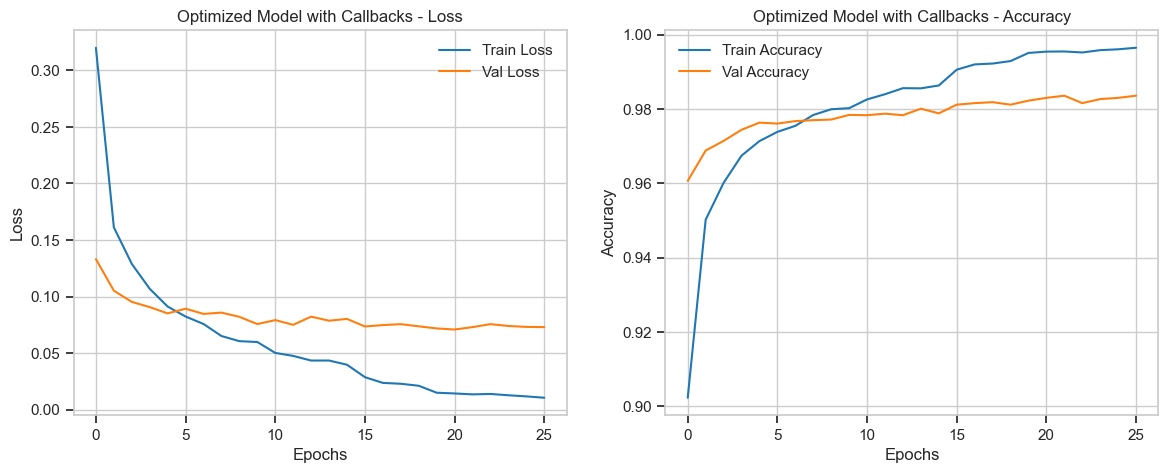

Optimized Test Accuracy: 0.9838
  1/313 ━━━━━━━━━━━━━━━━━━━━ 37s 119ms/step

 26/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step   

 55/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

 88/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

116/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

...

252/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

277/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

307/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


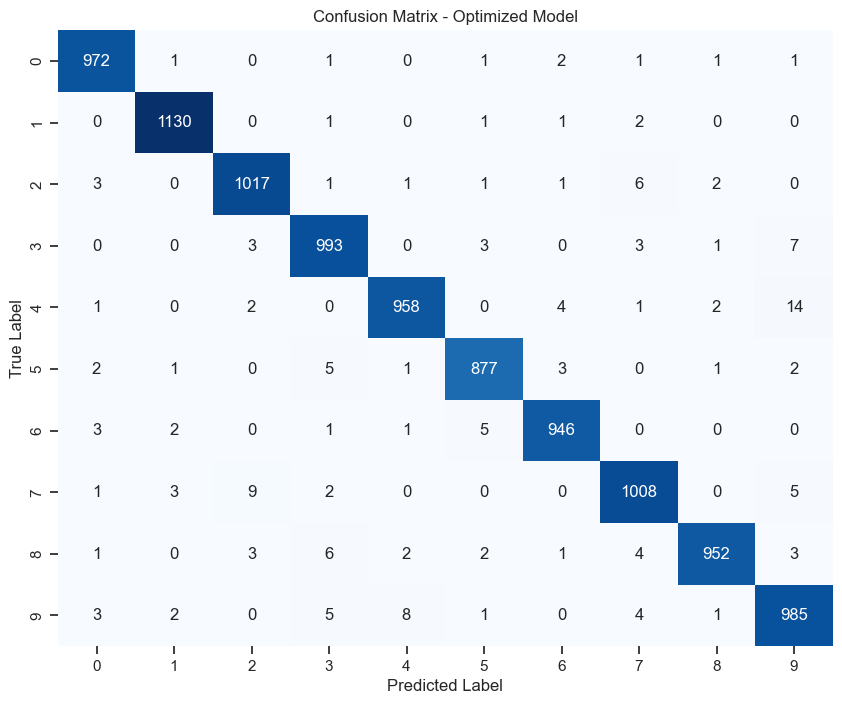


Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.98      0.99      0.98      1032
           3       0.98      0.98      0.98      1010
           4       0.99      0.98      0.98       982
           5       0.98      0.98      0.98       892
           6       0.99      0.99      0.99       958
           7       0.98      0.98      0.98      1028
           8       0.99      0.98      0.98       974
           9       0.97      0.98      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



In [10]:
# Evaluación final
plot_history(history_optim, "Optimized Model with Callbacks")

test_loss_opt, test_acc_opt = optimized_model.evaluate(X_test, y_test, verbose=0)
print(f"Optimized Test Accuracy: {test_acc_opt:.4f}")

# Matriz de confusión
y_pred_probs = optimized_model.predict(X_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Optimized Model')
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred_classes))

### 6. Análisis Profundo de Resultados

#### 6.1 Dinámica de Convergencia y Callbacks
El comportamiento de la red optimizada confirma que el control dinámico es superior a los hiperparámetros estáticos:

* **Optimización del Learning Rate:** Iniciamos con una tasa de 0.001. Los logs muestran que `ReduceLROnPlateau` la redujo a 0.0005 a partir de la época 16 (al no mejorar `val_loss` durante 3 épocas seguidas), y de nuevo a 0.00025 a partir de la época 20, y a 0.000125 a partir de la época 25. Esta desaceleración progresiva es crucial para permitir que el optimizador navegue por la superficie de pérdida hacia un mínimo más fino, evitando las oscilaciones bruscas que vimos en el modelo baseline.

* **Efectividad del EarlyStopping:** El mejor desempeño en validación ocurrió en la **época 21** (`val_loss`: 0.0709). Dado que la paciencia se configuró en 5, el entrenamiento continuó hasta la **época 26** para confirmar que no habría mejoras adicionales, y se detuvo ahí (de las 30 épocas máximas), restaurando los pesos de la época 21. Esto evitó un gasto innecesario de cómputo y protegió al modelo de empezar a memorizar ruido (overfitting): entre la época 21 y la 26, `val_loss` se mantuvo entre 0.0730 y 0.0756, sin volver a bajar de 0.0709.

#### 6.2 Diagnóstico de Errores (Error Analysis)
Al evaluar el desempeño final mediante la Matriz de Confusión y el reporte de clasificación (exactitud en prueba: **98.38 %**):

* **Ambigüedad Morfológica:** La confusión más frecuente de toda la matriz es, igual que se esperaba, entre el **4** y el **9**: 14 cuatros verdaderos se predijeron como 9, y 8 nueves verdaderos se predijeron como 4. También aparecen confusiones notables entre el **7** y el **2** (9 casos de 7 predichos como 2) y entre el **3** y el **9** (7 casos de 3 predichos como 9). Esto es un límite intrínseco de los MLPs, ya que procesan la imagen de forma aplanada (*flatten*), perdiendo la relación espacial jerárquica que una Red Convolucional (CNN) sí podría captar. Para mitigar esto sin cambiar de arquitectura, se recomienda el uso de **Data Augmentation** para forzar al modelo a ser invariante a rotaciones o traslaciones.
* **Calidad de la Muestra:** Algunos errores en el set de validación corresponden a trazos ambiguos o ruidosos donde la frontera de decisión es subjetiva incluso para un ojo humano. El hecho de alcanzar un **98.38 %** de exactitud en prueba (precision y recall de 0.97 a 0.99 por clase) indica que el modelo ha capturado la esencia estructural de la mayoría de los dígitos.

### 7. Conclusiones y Discusión Final

* **Aprendizaje vs. Memorización:** Los resultados del modelo *Baseline* son una lección clásica: un `accuracy` de entrenamiento del **99.80 %** (época 15) no garantiza éxito, y en prueba se queda en 97.72 %. La brecha frente al set de validación nos indica que la red estaba empezando a memorizar el ruido del dataset en lugar de generalizar las formas de los dígitos. En Deep Learning, un modelo con menor precisión en entrenamiento pero mejor regularizado siempre será preferible en producción: el modelo optimizado llegó a 99.65 % de entrenamiento pero superó al baseline en prueba (98.38 % frente a 97.72 %).

* **El impacto de la arquitectura híbrida:** No se trata solo de apilar capas `Dense`. La verdadera mejora vino de integrar Batch Normalization y Dropout. Mientras la primera estabilizó el flujo de los gradientes, la segunda forzó a la red a aprender representaciones redundantes y robustas, evitando que dependiera de neuronas específicas.

* **Estrategias Dinámicas (Callbacks):** El experimento demostró que los hiperparámetros estáticos son limitados. El uso de `ReduceLROnPlateau` fue clave a partir de la época 16, cuando redujo la "velocidad" de aprendizaje y permitió al optimizador explorar el fondo de la superficie de pérdida con mayor fineza (el `val_loss` siguió bajando de 0.0736 a 0.0709 entre las épocas 16 y 21). Por su parte, `EarlyStopping` con `restore_best_weights=True` nos da la tranquilidad de que, aunque el entrenamiento siguió hasta la época 26, el modelo final conserva los pesos de la época 21, la de mejor `val_loss` (0.0709), y no los de una época posterior ya en ligero sobreajuste.

* **Diagnóstico mediante curvas:** El monitoreo del *gap* entre entrenamiento y validación es, probablemente, la herramienta más potente que tenemos. Este ejercicio confirma que el diseño de una red neuronal es un proceso iterativo de balance entre capacidad (profundidad) y control (regularización).

### 8. Ejercicios

**Ejercicio 1.** Teniendo en cuenta la explicación de la sección *2.4*, cree un modelo con la misma estructura que `baseline_model` empleando únicamente la función de activación `"linear"` y entrenelo. ¿Cómo afecta esto el rendimiento de la red? ¿Por qué ocurre esto?

**Ejercicio 2.** A partir del modelo desarrollado en el *Ejercicio 1*, determine la matriz de pesos $W$ y el vector de sesgos $b$ que permitan representar la red neuronal en su forma equivalente $y=W^T X + b$. Utilice el atributo `.layers[]` y el método `.get_weights()` para extraer los parámetros. Finalmente, verifique la validez de su representación demostrando que, ante una misma imagen de entrada, tanto la red original como la representación equivalente producen el mismo resultado.

**Ejercicio 3.** Cree una nueva instancia del modelo `optimized_model` y entrénela utilizando un `batch_size` igual al tamaño total del conjunto de entrenamiento (`len(X_train)`). Analice los resultados y responda: ¿Qué efectos tiene este cambio sobre el desempeño del modelo y qué impacto produce en el cálculo del gradiente?


**Ejercicio 4.** ¿Cuál sería el comportamiento de las redes si se les proporcionara como entrada una imagen compuesta por datos completamente aleatorios? Plantee una hipótesis sobre la salida esperada en estos casos. Luego, genere una imagen aleatoria mediante la función `np.random.rand()` y evaluela en los modelos `baseline_model` y `optimized_model` para observar las probabilidades resultantes. ¿Coinciden los resultados con su hipótesis inicial? ¿Cómo explica estos resultados?

## Desarrollo de los ejercicios

### Ejercicio 1. Modelo con activación lineal

Construimos un modelo con la misma estructura que `baseline_model` (una capa oculta de 128 neuronas y una capa de salida de 10), pero cambiando **todas** las activaciones a `'linear'` (la identidad), y lo entrenamos con el mismo `batch_size` y número de `epochs` que el baseline para que la comparación sea justa.

In [11]:
def build_linear_model():
    model = keras.Sequential([
        layers.Flatten(input_shape=(28, 28)),
        layers.Dense(128, activation='linear'),
        layers.Dense(10, activation='linear')
    ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

linear_model = build_linear_model()
linear_model.summary()

C:\Users\opanadero\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history_linear = linear_model.fit(
    X_train, y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2,
    verbose=1
)

Epoch 1/15


  1/375 ━━━━━━━━━━━━━━━━━━━━ 6:30 1s/step - accuracy: 0.0469 - loss: 10.4842

 17/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2679 - loss: 5.4788  

 33/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3580 - loss: 3.8322

 48/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3757 - loss: 3.2523

...

320/375 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1850 - loss: 1.5393

336/375 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1836 - loss: 1.5382

355/375 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1831 - loss: 1.5351

373/375 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1818 - loss: 1.5337

375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.1817 - loss: 1.5334 - val_accuracy: 0.1715 - val_loss: 1.5354


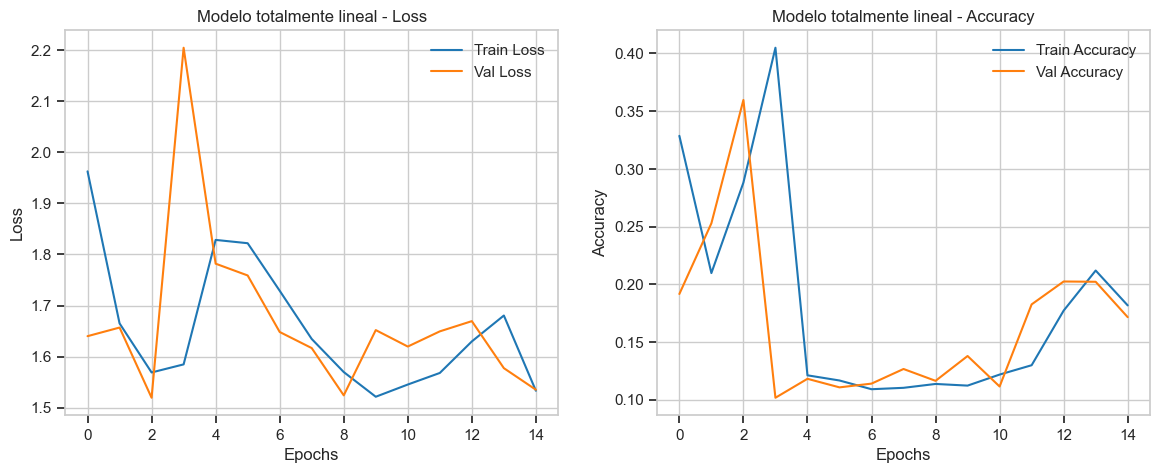

Baseline (ReLU + Softmax)  - Test Accuracy: 0.9772
Modelo totalmente lineal   - Test Accuracy: 0.1752


In [13]:
plot_history(history_linear, 'Modelo totalmente lineal')

test_loss_lin, test_acc_lin = linear_model.evaluate(X_test, y_test, verbose=0)
print(f'Baseline (ReLU + Softmax)  - Test Accuracy: {test_acc:.4f}')
print(f'Modelo totalmente lineal   - Test Accuracy: {test_acc_lin:.4f}')

**Resultado.** La exactitud en prueba del modelo totalmente lineal fue de apenas **17.52 %**, frente al **97.72 %** del baseline (ReLU + Softmax) — solo un poco por encima del 10 % que daría adivinar al azar entre 10 clases. Además, a diferencia de la curva suave y monótona del baseline, el entrenamiento del modelo lineal fue **errático**: el `accuracy` de entrenamiento osciló entre 0.11 y 0.40 de una época a otra, sin converger, y la pérdida se mantuvo entre 1.5 y 2.2 sin bajar de forma sostenida.

**Por qué ocurre.** Hay dos efectos distintos, y es importante no confundirlos:

1. **Pérdida de expresividad (sección 2.4 y proposición 9.1 de la lectura de la semana).** Al quitar la no linealidad entre las dos capas densas, su composición deja de ser una red de dos capas y se vuelve matemáticamente equivalente a una **única transformación afín** $y = x W_{eq} + b_{eq}$ (esto se verifica explícitamente en el Ejercicio 2). Eso por sí solo ya limita al modelo al techo de un clasificador lineal sobre los píxeles crudos, sin la jerarquía de características que permite una capa oculta no lineal.
2. **Una pérdida mal definida para esta salida.** El problema más grave es que la capa de salida también perdió el `softmax`: sus valores ya no son una distribución de probabilidad (pueden ser negativos o mayores que 1, como se ve en el Ejercicio 2, donde una de las salidas vale 14.0). `sparse_categorical_crossentropy`, sin embargo, espera recibir probabilidades. Al aplicarla sobre valores sin esa restricción, el gradiente que recibe la red deja de corresponder a una pérdida de clasificación bien definida, lo que explica el entrenamiento inestable y oscilante observado, más allá del simple techo teórico de un modelo lineal.

### Ejercicio 2. Representación equivalente $y = W^T X + b$

Como las dos capas densas del `linear_model` del Ejercicio 1 no tienen ninguna no linealidad entre ellas, su composición es, según la sección *9* de la lectura de la semana, una única función afín. Extraemos los pesos y sesgos de cada capa con `.get_weights()` y los componemos manualmente. Si $h = x W_1 + b_1$ y $y = h W_2 + b_2$ (convención de Keras, donde cada `kernel` tiene forma `(entradas, neuronas)`), entonces $y = x (W_1 W_2) + (b_1 W_2 + b_2)$.

In [14]:
W1, b1 = linear_model.layers[1].get_weights()  # Dense(128), capa 0 es Flatten
W2, b2 = linear_model.layers[2].get_weights()  # Dense(10)

W_eq = W1 @ W2
b_eq = b1 @ W2 + b2

print(f'W1: {W1.shape}, W2: {W2.shape}  ->  W equivalente: {W_eq.shape}')
print(f'b1: {b1.shape}, b2: {b2.shape}  ->  b equivalente: {b_eq.shape}')

W1: (784, 128), W2: (128, 10)  ->  W equivalente: (784, 10)
b1: (128,), b2: (10,)  ->  b equivalente: (10,)


In [15]:
x_prueba = X_test[0:1]                     # (1, 28, 28), igual que recibe la red
x_prueba_flat = x_prueba.reshape(1, -1)     # (1, 784), igual que recibe la forma equivalente

salida_red = linear_model.predict(x_prueba, verbose=0)[0]
salida_equivalente = (x_prueba_flat @ W_eq + b_eq)[0]

print('Salida de la red (linear_model):      ', np.round(salida_red, 4))
print('Salida de la forma equivalente W^T X+b:', np.round(salida_equivalente, 4))
print('Diferencia máxima absoluta:            ', np.max(np.abs(salida_red - salida_equivalente)))
print('¿Coinciden (tolerancia 1e-3)?          ', np.allclose(salida_red, salida_equivalente, atol=1e-3))

Salida de la red (linear_model):       [-3.0273 -6.104  14.0002 -4.0828 -7.957  -4.8041 -9.0097  4.9472 -6.6907
 -4.8388]
Salida de la forma equivalente W^T X+b: [-3.0273 -6.104  14.0002 -4.0828 -7.957  -4.8041 -9.0097  4.9472 -6.6907
 -4.8388]
Diferencia máxima absoluta:             2.861023e-06
¿Coinciden (tolerancia 1e-3)?           True


**Resultado.** La diferencia máxima absoluta entre la salida de `linear_model` y la salida de la forma equivalente $x W_{eq} + b_{eq}$, sobre la misma imagen de prueba, fue de **2.86 × 10⁻⁶** (`np.allclose(..., atol=1e-3)` devolvió `True`), una diferencia explicable únicamente por redondeo de punto flotante.

Esto confirma de forma empírica la proposición 9.1: con todas las activaciones iguales a la identidad, un MLP de cualquier profundidad **no representa nada que un único modelo afín no represente ya**. La "red" de dos capas de 128 y 10 neuronas (101 770 parámetros) es, en la práctica, indistinguible de multiplicar directamente la imagen aplanada por una matriz $W_{eq} \in \mathbb{R}^{784 \times 10}$ y sumar un vector $b_{eq} \in \mathbb{R}^{10}$: toda la profundidad adicional no aporta ninguna capacidad extra cuando no hay una función de activación no lineal entre las capas.

### Ejercicio 3. Entrenamiento con `batch_size = len(X_train)`

Entrenamos una nueva instancia de `optimized_model` con los mismos callbacks e hiperparámetros que en la sección 5, cambiando únicamente `batch_size` al tamaño completo del conjunto de entrenamiento. Con `validation_split=0.2`, Keras separa primero el 20 % de validación, así que en la práctica cada época hace **un solo paso de descenso de gradiente** sobre el 80 % restante, en lugar de los cientos de pasos (con lotes pequeños) de la sección 5.

In [16]:
optimized_model_fullbatch = build_optimized_model()

early_stopping_fb = callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)
reduce_lr_fb = callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6
)

history_fullbatch = optimized_model_fullbatch.fit(
    X_train, y_train,
    batch_size=len(X_train),
    epochs=30,
    validation_split=0.2,
    callbacks=[early_stopping_fb, reduce_lr_fb],
    verbose=1
)

Epoch 1/30


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.1008 - loss: 3.1619

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.1008 - loss: 3.1619 - val_accuracy: 0.1832 - val_loss: 2.1764 - learning_rate: 0.0010


Epoch 2/30


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2770 - loss: 2.2495

...

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9154 - loss: 0.2838

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.9154 - loss: 0.2838 - val_accuracy: 0.8479 - val_loss: 0.8938 - learning_rate: 0.0010


Epoch 30/30


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9170 - loss: 0.2780

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.9170 - loss: 0.2780 - val_accuracy: 0.8538 - val_loss: 0.8803 - learning_rate: 0.0010


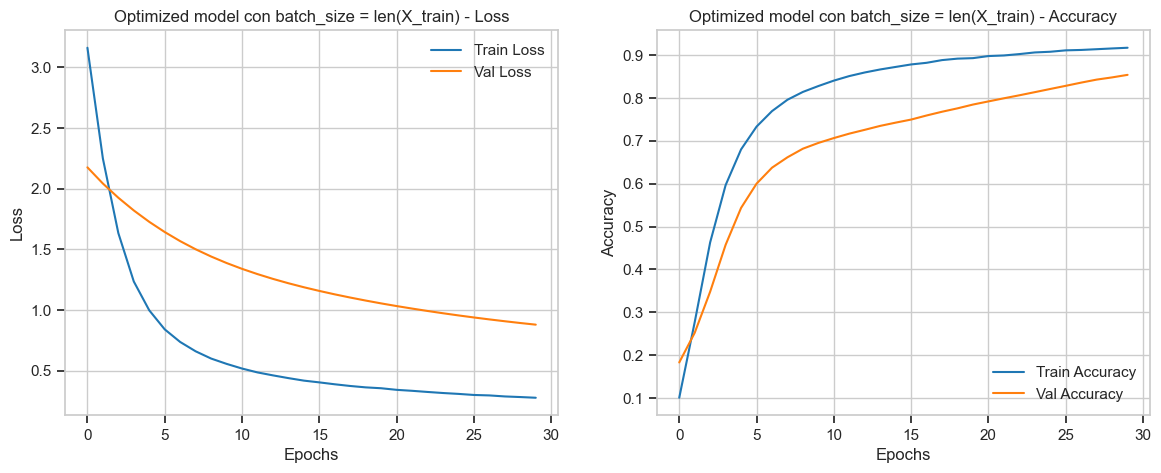

Optimized (batch_size=64)            - Épocas entrenadas: 26, Test Accuracy: 0.9838
Optimized (batch_size=len(X_train))  - Épocas entrenadas: 30, Test Accuracy: 0.8451


In [17]:
plot_history(history_fullbatch, 'Optimized model con batch_size = len(X_train)')

test_loss_fb, test_acc_fb = optimized_model_fullbatch.evaluate(X_test, y_test, verbose=0)
print(f'Optimized (batch_size=64)            - Épocas entrenadas: {len(history_optim.history["loss"])}'
      f', Test Accuracy: {test_acc_opt:.4f}')
print(f'Optimized (batch_size=len(X_train))  - Épocas entrenadas: {len(history_fullbatch.history["loss"])}'
      f', Test Accuracy: {test_acc_fb:.4f}')

**Resultado.** Con `batch_size=64` (sección 5), `EarlyStopping` detuvo el entrenamiento en la época 26 con 98.38 % de exactitud en prueba. Con `batch_size=len(X_train)`, el entrenamiento corrió las **30 épocas completas sin que se activara ni `EarlyStopping` ni una reducción efectiva del `learning_rate`** (el `val_loss` bajó de forma continua, de 2.18 en la época 1 a 0.88 en la época 30, sin estancarse), y aun así terminó con solo **84.51 %** de exactitud en prueba, muy por debajo del modelo con lotes pequeños.

**Efecto sobre el desempeño.** Con el mismo (o incluso mayor) número de épocas, el modelo con lote completo aprendió mucho menos.

**Impacto en el cálculo del gradiente.** La razón es el número de **actualizaciones de pesos**, no el número de épocas: con `batch_size=64` cada época recorre el conjunto de entrenamiento en unos 750 pasos (750 actualizaciones de los pesos por época, usando en cada una un gradiente *estocástico*, estimado sobre un lote pequeño y por tanto ruidoso). Con `batch_size=len(X_train)`, cada época es **un único paso** de descenso de gradiente, calculado sobre el gradiente exacto de todo el conjunto de entrenamiento (sin ruido, pero también sin aprovechar que cada paso es mucho más barato de dar). En 26 a 30 épocas, el modelo de la sección 5 dio entre 19 500 y 22 500 pasos de optimización, mientras que el de este ejercicio dio solo 30. El gradiente de lote completo es más "preciso" en cada paso, pero al dar tan pocos pasos en total, el modelo apenas empieza a converger cuando termina el entrenamiento — de hecho, la curva de `val_loss` todavía estaba bajando con fuerza en la época 30, señal de que con más épocas seguiría mejorando, pero a un costo de cómputo por punto porcentual de exactitud mucho mayor que con lotes pequeños.

### Ejercicio 4. Entrada completamente aleatoria

**Hipótesis.** Ninguno de los dos modelos fue entrenado con ruido puro como entrada, así que no hay ninguna razón para esperar que "sepan" que la imagen no es un dígito real. La capa de salida `softmax` siempre produce una distribución de probabilidad que suma 1 entre las 10 clases, sin importar qué tan absurda sea la entrada: el modelo **igual elegirá una clase con la mayor probabilidad relativa**, aunque esa probabilidad no signifique "confianza genuina" en ningún sentido útil. Es esperable, eso sí, que el modelo `optimized_model` (con Dropout y Batch Normalization, menos sobreajustado a los patrones exactos de MNIST) produzca una distribución algo más repartida entre varias clases que `baseline_model`, que al sobreajustarse más podría mostrarse "más seguro" de una clase incorrecta.

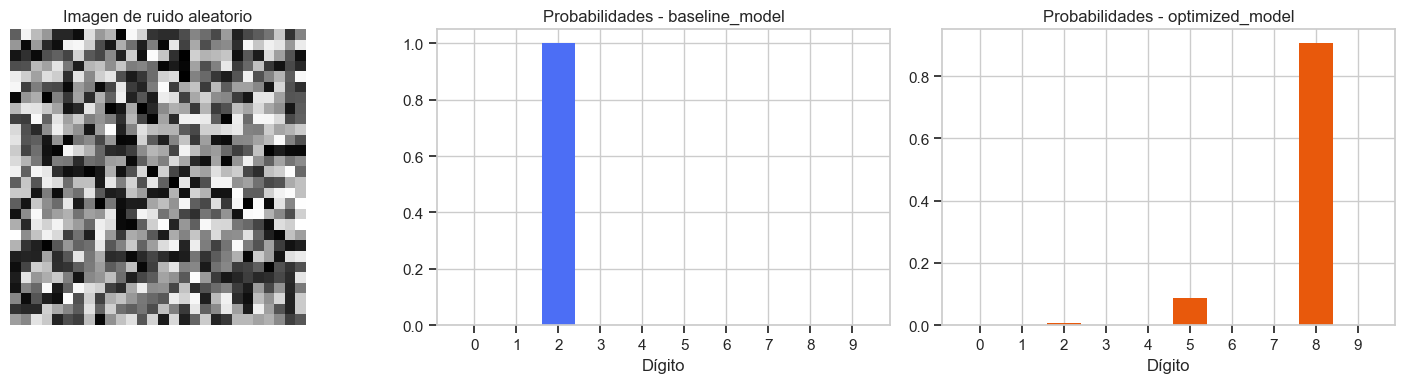

baseline_model  predice 2 con probabilidad 0.9998
optimized_model predice 8 con probabilidad 0.9051


In [18]:
imagen_aleatoria = np.random.rand(1, 28, 28).astype('float32')

probs_baseline = baseline_model.predict(imagen_aleatoria, verbose=0)[0]
probs_optim = optimized_model.predict(imagen_aleatoria, verbose=0)[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(imagen_aleatoria[0], cmap='gray')
axes[0].axis('off')
axes[0].set_title('Imagen de ruido aleatorio')

axes[1].bar(range(10), probs_baseline, color='#4C6EF5')
axes[1].set_xticks(range(10))
axes[1].set_title('Probabilidades - baseline_model')
axes[1].set_xlabel('Dígito')

axes[2].bar(range(10), probs_optim, color='#E8590C')
axes[2].set_xticks(range(10))
axes[2].set_title('Probabilidades - optimized_model')
axes[2].set_xlabel('Dígito')
plt.tight_layout()
plt.show()

print(f'baseline_model  predice {np.argmax(probs_baseline)} con probabilidad {probs_baseline.max():.4f}')
print(f'optimized_model predice {np.argmax(probs_optim)} con probabilidad {probs_optim.max():.4f}')

**Resultado.** Sobre la misma imagen de ruido aleatorio, `baseline_model` predijo el dígito **2 con 99.98 %** de probabilidad (una salida prácticamente one-hot, sin masa apreciable en ninguna otra clase), mientras que `optimized_model` predijo el dígito **8 con 90.51 %**, con un 9 % adicional repartido principalmente en el dígito 5 y una fracción mínima en el 2.

Esto confirma la hipótesis: ninguno de los dos modelos reconoce que la entrada no es un dígito real, porque `softmax` está matemáticamente obligado a producir una distribución de probabilidad que suma 1 sobre las 10 clases, sin ninguna opción de "no sé" o "esto no es un dígito". Una probabilidad alta en la salida de un MLP clásico no es una medida confiable de si la entrada se parece a los datos de entrenamiento, solo de cuál clase es relativamente más consistente con los pesos aprendidos, incluso para una entrada completamente fuera de la distribución de MNIST.

También se confirma la segunda parte de la hipótesis, aunque de forma modesta: `baseline_model`, sin ninguna regularización, produce una predicción extremadamente segura (99.98 %) y totalmente concentrada en una clase, mientras que `optimized_model`, entrenado con Dropout y Batch Normalization, reparte una fracción (aunque pequeña) de probabilidad hacia una segunda clase. La diferencia es real pero no dramática: ambos modelos siguen estando, en términos absolutos, muy "seguros" de una predicción que no tiene ningún sentido para una imagen de ruido puro.